# 02 · Decline curve analysis

**Question:** how fast was each main well declining, can a simple curve predict it, and how much oil was left when the field shut in during 2016?

Wells: **F-12, F-14, F-11** (the only producers with enough history; together about 96% of field oil).

Approach:
1. Monthly **producing-day rate** = oil ÷ on-stream days, so a shutdown month doesn't look like decline.
2. Fit two Arps models in log space: **exponential** `q = qi·e^(-D·t)` and **hyperbolic** `q = qi / (1 + b·D·t)^(1/b)`.
3. **Backtest:** fit on data before 2016, score on 2016, and compare against a naive baseline (hold the last 3 months' average flat).
4. Refit on all data and project to an **economic limit** to estimate remaining oil.

All logic lives in `python/decline_curves.py`; this notebook runs it and explains the results.

In [1]:
import sys; sys.path.insert(0, '../python')
import pandas as pd
import decline_curves as dc
pd.set_option('display.float_format', '{:,.1f}'.format)
m = dc.monthly_rates('../data/processed/production_daily_clean.csv')
m[m['well'].isin(dc.WELLS)].groupby('well')[['month']].agg(['min', 'max', 'count'])

month                 
                 min        max count
well                                 
15/9-F-11 2013-07-01 2016-09-01    39
15/9-F-12 2008-02-01 2016-09-01   104
15/9-F-14 2008-02-01 2016-09-01   104

## Choosing the fit window

Fitting a well's whole history is wrong here for two reasons:

- **Restarts.** F-12's rate jumped from ~180 to ~860 Sm³/d in January 2015 after a shut-in, probably a well intervention (the data doesn't say). The old decline no longer applies after that.
- **The decline speeds up as water cut rises.** Old, flatter data drags the curve too flat.

Rule used for every well (data before the forecast date only):
1. Find the last month whose rate rose 30%+ over the previous producing month (a restart).
2. Start at the peak rate after that restart.
3. Never look back more than 24 months.
4. Skip months with fewer than 10 producing days (too noisy).

In [2]:
for w in dc.WELLS:
    print(w, 'backtest fit starts', dc.fit_window_start(m[m['well'] == w], dc.BACKTEST_CUTOFF).strftime('%Y-%m'))

15/9-F-12 backtest fit starts 2015-01
15/9-F-14 backtest fit starts 2014-01
15/9-F-11 backtest fit starts 2015-04


## Backtest: fit before 2016, score on 2016

In [3]:
bt, bt_curves = dc.backtest(m)
bt.pivot(index='well', columns='model', values='mape_pct').loc[dc.WELLS]

model,exp,hyp,naive
well,,,
15/9-F-12,24.6,25.0,94.0
15/9-F-14,7.3,18.1,52.9
15/9-F-11,30.4,43.4,104.8


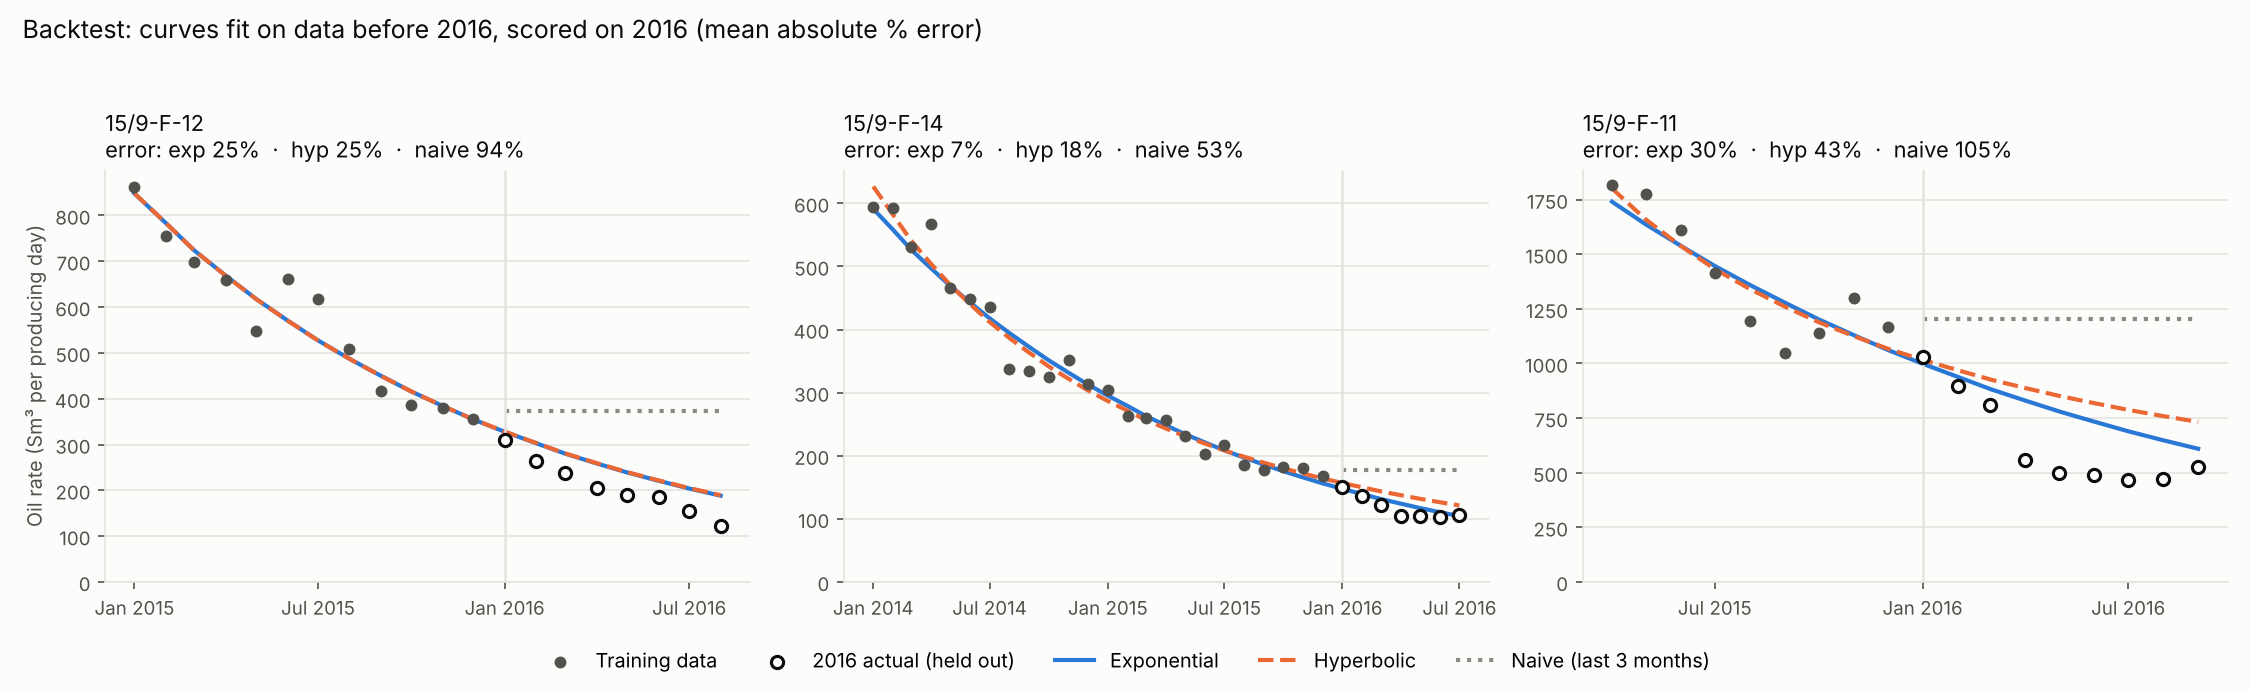

In [4]:
dc.plot_backtest(bt_curves, bt, '../images/decline_backtest.png')
from IPython.display import Image; Image('../images/decline_backtest.png')

**Read-out**

- **Both curves beat the naive baseline on every well** (errors of 7–43% vs 53–105%). Assuming "next year looks like the last few months" badly overstates a declining well.
- **Exponential was as good as or better than hyperbolic every time.** With 9–24 points, the extra `b` parameter mostly fits noise.
- **F-14 forecasts well (7% error)**: a long, steady decline.
- **F-12 and F-11 declined faster in 2016 than the curves predicted** (volume over-predicted by ~20–24%). For F-11, the rate dropped 31% in a single month (April 2016), a step change no smooth curve can anticipate.

**Why the 24-month cap:** fitting F-14 from its 2008 peak instead gives a much worse backtest:

In [5]:
dc.full_history_check(m)

{'well': '15/9-F-14',
 'fit_from': '2008-10',
 'mape_pct': np.float64(65.42136336218236)}

## Remaining oil at the 2016 shut-in

Refit on all data, then project with the exponential model (the backtest winner). Calendar volumes use each well's average uptime over its last 12 months. The economic limit is an **assumption**: the dataset has no cost data, so I show 50 / 100 / 150 Sm³ per producing day (about 315 / 630 / 945 bbl/d), with 100 as the base case.

In [6]:
fc, fc_curves = dc.forecast_remaining(m)
exp = fc[fc['model'] == 'exp']
exp.pivot(index='well', columns='econ_limit_sm3d', values='remaining_oil_sm3').loc[dc.WELLS]

econ_limit_sm3d,50,100,150
well,,,
15/9-F-12,"25,232.0","10,272.2",0.0
15/9-F-14,"24,276.8",0.0,0.0
15/9-F-11,"118,512.1","101,740.7","87,572.3"


In [7]:
exp[exp['econ_limit_sm3d'] == 100][['well', 'last_rate_sm3d', 'fitted_annual_decline_pct', 'limit_reached', 'remaining_oil_sm3', 'remaining_oil_bbl']]

,well,last_rate_sm3d,fitted_annual_decline_pct,limit_reached,remaining_oil_sm3,remaining_oil_bbl
1,15/9-F-12,121.1,68.9,2016-11,"10,272.2","64,609.8"
7,15/9-F-14,105.7,49.9,already below,0.0,0.0
13,15/9-F-11,526.7,64.7,2018-01,"101,740.7","639,928.8"


In [8]:
fc[fc['model'] == 'hyp'][['well', 'hyp_b']].drop_duplicates()  # hyperbolic collapses to exponential (b at its lower bound)

,well,hyp_b
3,15/9-F-12,0.0
9,15/9-F-14,0.0
15,15/9-F-11,0.0


## F-11: the one forecast that depends on a judgment call

F-11's rate fell sharply in early 2016, then held flat at ~470–530 Sm³/d for six months. Whether that flat stretch is the new normal changes the answer by about 7×:

In [9]:
sens, sens_curves = dc.window_sensitivity(m)
sens

,well,fit_from,fit_months,annual_decline_pct,limit_reached,remaining_oil_sm3,remaining_oil_bbl
0,15/9-F-11,2015-04,18,64.7,2018-01,"101,740.7","639,928.8"
1,15/9-F-11,2016-01,9,68.9,2017-11,"84,620.4","532,245.5"
2,15/9-F-11,2016-04,6,15.9,2025-09,"736,920.0","4,635,079.2"


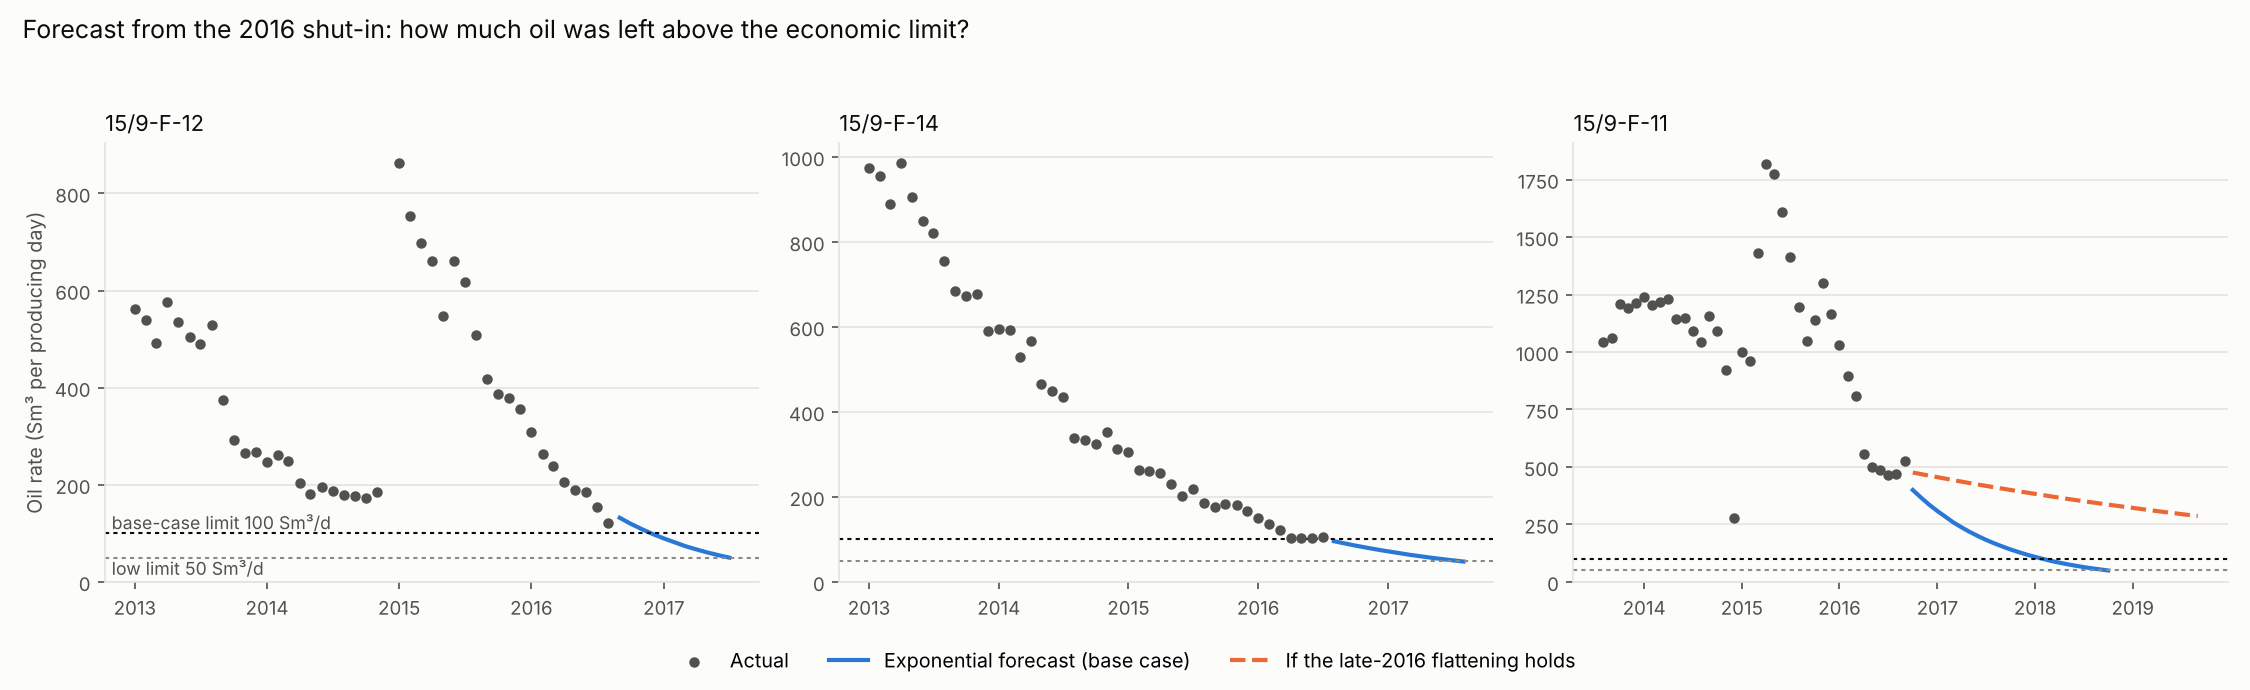

In [10]:
dc.plot_forecast(m, fc_curves, sens_curves, '../images/decline_forecast.png')
Image('../images/decline_forecast.png')

## Conclusions

1. **F-12 and F-14 were at the end of their economic life when the field shut in.** F-14 was already at ~100 Sm³/d; F-12 would have reached it within about three months. Even at a 50 Sm³/d limit, each had only ~25,000 Sm³ left.
2. **F-11 was the only well with meaningful oil left**: about 100,000 Sm³ (~0.64 MMbbl) above 100 Sm³/d in the base case, and possibly several times that if its late-2016 rate had held.
3. **Base-case remaining oil across the three wells is ~112,000 Sm³ (~0.7 MMbbl), about 1% of what they had already produced.** The backtest showed the curves running optimistic for F-12, so that number leans high for F-12 and low for F-11.
4. **Method:** a simple exponential on a recent window beat both a hyperbolic fit and a naive baseline. Window choice mattered more than model choice.

**Limits:** no pressure, cost, or intervention records; economic limit is assumed; rates are well-level and ignore platform constraints (water handling, shared facilities). This is the kind of first-pass screen an engineer would refine with reservoir data, not a reserves booking.